# Оглавление

1. [Lab01 - sprint 1](#lab01---sprint-1)
2. [Dataset preparation](#dataset-preparation)
3. [General description (природа событий)](#general-description-природа-событий)
   - [Выборка с возвращением и без возвращения](#выборка-с-возвращением-и-без-возвращения)
4. [Random Variable Mass](#random-variable-mass)
5. [Random Variable Body Lenght](#random-variable-body-lenght)
6. [Random Variable Humerus Length](#random-variable-humerus-length)
7. [Random Variable Femural Length](#random-variable-femural-length)
8. [Выделение зависимостей](#выделение-зависимостей)
   - [Проверка зависимости](#проверка-зависимости)
   - [Графики величин](#графики-величин)
   - [Корреляционный анализ](#корреляционный-анализ)
   - [Нормализация. Диаграмма размаха](#нормализация-диаграмма-размаха)
9. [Доп задание по массе](#доп-задание-по-массе)
   - [Создание выборок без возвращения, каждая по 50 значениями](#создание-выборок-без-возвращения-каждая-по-50-значениями)
   - [Рассчитываем характеристики всех выборок](#рассчитываем-характеристики-всех-выборок)
   - [Сравниваем характеристики с генеральной совокупностью](#сравниваем-характеристики-с-генеральной-совокупностью)
   - [Графики сравнения характеристик](#графики-сравнения-характеристик)
10. [Lab resume](#lab-resume)

# Lab01 - sprint 1

Вопросы/гипотезы: зависят ли масса тела, длина тела, длина плечевой кости и длина бедренной кости от пола и доли китайсеого происхождения у макак?, есть ли зависимости между этими величинами?
Для ответа исследуем четыре случайные случайные величины: массу тела, длину тела, длину плечевой кости и длину бедренной кости.

## Dataset preparation

Подключение библиотек и загрузка датасета: https://onlinelibrary.wiley.com/doi/10.1002/ajpa.25062

In [80]:
%pip install pandas xlrd

Note: you may need to restart the kernel to use updated packages.


Вывод первых нескольких строк (проверка)

In [81]:
import pandas as pd

toque = pd.read_excel("Макаки.xlsx")
toque.head()

,Specimen,Sex,Chinese Ancestry,kg,C-R curved,R humeral max,R femoral max,R Radial max,R tibial max,Note
0,29999,F,0.250,9.30,507.1,153.17,181.65,155.01,166.04,NaN
1,30797,F,0.125,8.49,531.6,156.21,179.04,154.70,166.48,NaN
2,31603,F,0.750,7.35,514.4,152.38,174.42,139.60,155.81,NaN
3,31692,F,0.750,7.70,531.7,147.33,165.06,144.37,152.57,NaN
4,32200,F,0.130,8.50,531.6,150.25,173.47,148.20,156.72,NaN


Просмотр таблицы, что была до отсева ненужной части данных

In [82]:
toque.info()

<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Specimen          134 non-null    int64  
 1   Sex               134 non-null    str    
 2   Chinese Ancestry  134 non-null    float64
 3   kg                134 non-null    float64
 4   C-R curved        134 non-null    float64
 5   R humeral max     134 non-null    float64
 6   R femoral max     134 non-null    float64
 7   R Radial max      134 non-null    float64
 8   R tibial max      134 non-null    float64
 9   Note              2 non-null      str    
dtypes: float64(7), int64(1), str(2)
memory usage: 10.8 KB


Создание таблицы только с тремя величинами, подсчёт строк с отсутствующими данными

In [83]:
selected = toque[["Sex", "Chinese Ancestry", "kg", "C-R curved", "R humeral max", "R femoral max"]].copy()
selected.isna().sum()

Sex                 0
Chinese Ancestry    0
kg                  0
C-R curved          0
R humeral max       0
R femoral max       0
dtype: int64

Создание таблицы только со строками с полными данными

In [84]:
complete = selected.dropna()
print("Всего строк:", len(selected))
print("Строк со всеми тремя измерениями:", len(complete))
print("Строк хотя бы с одним пропуском:", len(selected) - len(complete))

Всего строк: 134
Строк со всеми тремя измерениями: 134
Строк хотя бы с одним пропуском: 0


Создание таблиц выборки

In [85]:
sample_with = complete.sample(n=50, replace=True, random_state=42)
sample_without = complete.sample(n=50, replace=False, random_state=43)
sample_males = complete[complete["Sex"] == "M"].copy()
sample_females = complete[complete["Sex"] == "F"].copy()
print("Самцов:", len(sample_males))
print("Самок:", len(sample_females))

Самцов: 42
Самок: 92


<a id="general-description"></a>
## General description (природа событий)

Из 134 строки с полными данными равновероятно выбирается одна строка о конкретном животном. Животное не выбрано, пока не выбрана строка с данными. Каждой строке соответствуют фиксированные, конкретные значения массы тела, длины тела, плечевой и бедренной кости. 134 строки - это генеральная совокупность.

$$
\Omega = \{\omega_1,\ldots,\omega_{134}\}, \qquad
P(\omega_j) = \frac{1}{134}, \qquad j=1,\ldots,134.
$$

При равновероятном выборе строки величины массы тела и три длины имеют дискретное распределние с конечных числом возможных значений. До случайного выбора животного неизвестно, какое значение примет (X).

$$
P(X=x_i)=p_i=\frac{n_i}{N},\qquad N=134.
$$

<a id="sampling"></a>
### Выборка с возвращением и без возвращения

Из генеральной совокупности выбирается выборка размером n.

При отборе с возвращением: после взятия животного в выборку, оно остаётся доступным, чтобы вязть его снова. То есть конкретное данное животное в выборке может встретиться несколько раз. Выбор животного остаётся одинаковым для каждого животного. Число животных в выборке может быть больше, чем число животных в генерельной совокупности.

При отборе без возвращения: после взятия животного в выборку, оно становится недоступным, чтобы взять его снова. То есть любое животное в выборке может встретиться только один раз. Число животных в выборке не может быть больше, чем число животных в генерельной совокупности.

Среднее генеральной совокупности и её дисперсия:
$$
\mu=\frac{1}{N}\sum_{j=1}^{N}x_j,
\qquad
\sigma^2=\frac{1}{N}\sum_{j=1}^{N}(x_j-\mu)^2.
$$
Выборочное среднее:
$$
\bar X=\frac{1}{n}\sum_{i=1}^{n}X_i
$$

Дисперсии выборок различаются:
$$
\sigma_{\bar X,\;\text{с возвращением}}^{2}
=\frac{\sigma^2}{n}
$$

$$
\sigma_{\bar X,\;\text{без возвращения}}^{2}
=\frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}
$$

<a id="mass"></a>
## Random Variable Mass

### Description (природа события)

Случайная величина (X) - масса тела животного в выбранной строке с единицей измерения [кг].
Только после выбора строки можно узнать массу, то есть величина заранее не известна. Но каждой конкретной строке соответствует одна масса. Это соответствует определению случайной величины у Н.Ш.Кремера (стр.89-90).

$$
X(\omega_j) = m_j
$$

### EDA & Distribution

До случайного выбора животного неизвестно, какое значение примет (X).

$$
P(X=x_i)=p_i=\frac{n_i}{N}, \qquad
p_i \geq 0, \qquad \sum_{i=1}^{k}p_i=1.
$$

#### Была построена гистограмма распределения масс животных.

Распределение в исходной гистограмме масс животных визуально не является нормальным, поэтому массы были прологарифмированы (взят десятичный логарифм). Распределение на логарифмируемом графике визуально похоже на нормальное. Сделано предположение, что распределение логнормальное.

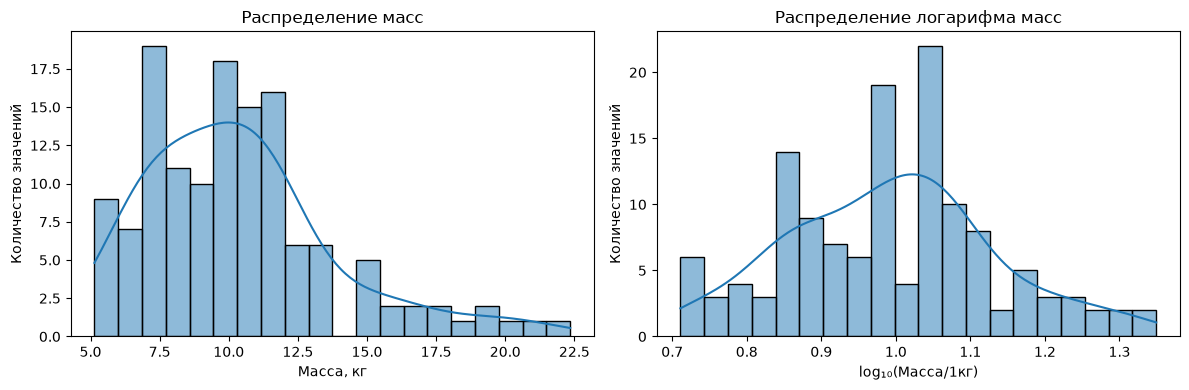

In [86]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

mass = complete["kg"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x=mass, bins=20, kde=True,edgecolor="black", ax=axes[0])
axes[0].set_title("Распределение масс")
axes[0].set_xlabel("Масса, кг")
axes[0].set_ylabel("Количество значений")
sns.histplot(x=np.log10(mass), bins=20, kde=True,edgecolor="black", ax=axes[1])
axes[1].set_title("Распределение логарифма масс")
axes[1].set_xlabel("log₁₀(Масса/1кг)")
axes[1].set_ylabel("Количество значений")
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
plt.tight_layout()
plt.show()

Подтвержение нормального распределения логарифма масс с помощью Q-Q-графика. (Подтверждение логнормального распределения.)

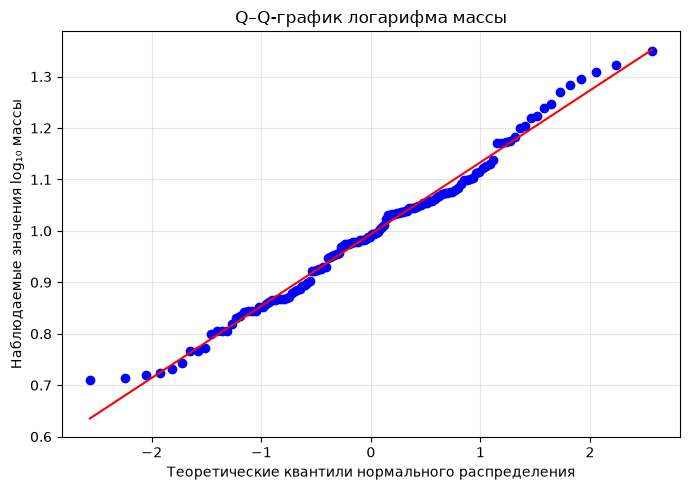

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

mass = pd.to_numeric(selected["kg"].astype(str).str.replace(",", ".", regex=False),errors="coerce").dropna()
log_mass = np.log10(mass[mass > 0])
fig, ax = plt.subplots(figsize=(7, 5))
stats.probplot(log_mass, dist="norm", plot=ax)
ax.set_title("Q–Q-график логарифма массы")
ax.set_xlabel("Теоретические квантили нормального распределения")
ax.set_ylabel("Наблюдаемые значения log₁₀ массы")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Построение графиков функции распределения массы

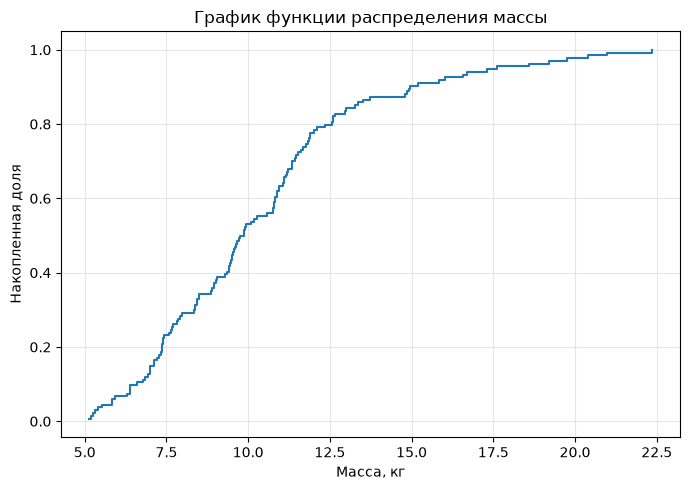

In [89]:
mass_table = mass_table.sort_values("mass_kg")
mass_table["P"] = mass_table["p_i"].cumsum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.step(mass_table["mass_kg"], mass_table["P"], where="post")
ax.set_title("График функции распределения массы")
ax.set_xlabel("Масса, кг")
ax.set_ylabel("Накопленная доля")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Вычисление разных статистик масс (математического ожидания, среднего, дисперсии, стандратного отклонения, моды и тд)

$$
\mu_X=E[X]=\sum_{i=1}^{k}x_i p_i, \qquad
D(X)=\sum_{i=1}^{k}(x_i-\mu_X)^2p_i,
\qquad \sigma_X=\sqrt{D(X)}.
$$

In [90]:
expected_mass = (mass_table["mass_kg"] * mass_table["p_i"]).sum()
variance_mass = ((mass_table["mass_kg"] - mass.mean()) ** 2* mass_table["p_i"]).sum()
std_mass = np.sqrt(variance_mass)
modes_mass = mass.mode()
max_count = mass.value_counts().max()
print(f"Мат. ожидание по таблице частот, кг: {expected_mass:,.2f}")
print(f"Количество масс: {mass.count():,.2f}")
print(f"Сумма масс, кг: {mass.sum():.2f}")
print(f"Средняя масса, кг: {mass.mean():,.2f}")
print(f"Медиана массы, кг: {mass.median():,.2f}")
print(f"Минимальная масса, кг: {mass.min():,.2f}")
print(f"Максимальная масса, кг: {mass.max():,.2f}")
print(f"Cтандартное отклонение, кг: {mass.std(ddof=0):,.2f}")
print(f"Первый квартиль (25%), кг: {mass.quantile(0.25):,.2f}")
print(f"Третий квартиль (75%), кг: {mass.quantile(0.75):,.2f}")
print(f"95-й перцентиль, кг: {mass.quantile(0.95):,.2f}")
print(f"Дисперсия, кг²: {variance_mass:,.2f}")
print(f"Стандартное отклонение, кг: {std_mass:,.2f}")
print("Мода, кг:", modes_mass.tolist())
print("Число повторений каждой моды:", max_count)

Мат. ожидание по таблице частот, кг: 10.38
Количество масс: 134.00
Сумма масс, кг: 1390.65
Средняя масса, кг: 10.38
Медиана массы, кг: 9.82
Минимальная масса, кг: 5.14
Максимальная масса, кг: 22.35
Cтандартное отклонение, кг: 3.47
Первый квартиль (25%), кг: 7.67
Третий квартиль (75%), кг: 11.82
95-й перцентиль, кг: 17.41
Дисперсия, кг²: 12.07
Стандартное отклонение, кг: 3.47
Мода, кг: [7.0]
Число повторений каждой моды: 3


### Independence & Estimations

#### Состоятельность оценки

134 масса - это генеральная совокупность. Её средняя масса известна и используется как контроль.
Берём данные из генеральной выборки, получаем выборки с возвращением с разным количеством масс.
Для каждой новой выборки повторяем исследование 1000 раз, вычисляя выборочное среднее. Проверяем, уменьшается ли
с ростом объёма выборки ошибка оценки среднего (RMSE).

In [92]:
rng = np.random.default_rng(42)
population = complete["kg"].to_numpy()
true_mean = population.mean()
sample_sizes = [10, 30, 100, 300, 1000, 3000]
repeats = 1000
results = []
for n in sample_sizes:
    samples = rng.choice(population,size=(repeats, n),replace=True)
    estimates = samples.mean(axis=1)
    errors = estimates - true_mean
    results.append({
        "Размер выборки": n,
        "Среднее оценок, кг": estimates.mean(),
        "RMSE, кг": np.sqrt(np.mean(errors ** 2)),
        "Нижняя граница 95% оценок, кг": np.quantile(estimates, 0.025),
        "Верхняя граница 95% оценок, кг": np.quantile(estimates, 0.975)
    })
consistency_mass = pd.DataFrame(results)
print(f"Средняя масса генеральной совокупности: {true_mean:.2f} кг")
display(consistency_mass)

Средняя масса генеральной совокупности: 10.38 кг


,Размер выборки,"Среднее оценок, кг","RMSE, кг","Нижняя граница 95% оценок, кг","Верхняя граница 95% оценок, кг"
0,10,10.357613,1.110478,8.405925,12.737175
1,30,10.347124,0.631364,9.202400,11.657517
2,100,10.359417,0.355113,9.675387,11.064650
3,300,10.391260,0.207961,9.998503,10.811438
4,1000,10.376276,0.107659,10.172362,10.596813
5,3000,10.373561,0.060731,10.257732,10.497122


#### Ошибка оценки среднего от размера выборки

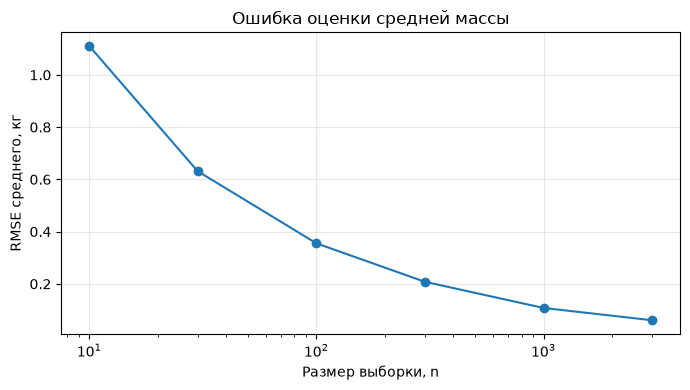

In [93]:
plt.figure(figsize=(7, 4))
plt.plot(consistency_mass["Размер выборки"], consistency_mass["RMSE, кг"], marker="o")
plt.xscale("log")
plt.xlabel("Размер выборки, n")
plt.ylabel("RMSE среднего, кг")
plt.title("Ошибка оценки средней массы")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Вычисление разных статистик масс тел в выборке с возвращением

In [94]:
mass_with = sample_with["kg"]
print("Количество:", mass_with.count())
print(f"Среднее, кг: {mass_with.mean():.2f}")
print(f"Медиана, кг: {mass_with.median():.2f}")
print(f"Минимум, кг: {mass_with.min():.2f}")
print(f"Максимум, кг: {mass_with.max():.2f}")
print(f"Стандартное отклонение, кг: {mass_with.std(ddof=0):.2f}")
print(f"Первый квартиль, кг: {mass_with.quantile(0.25):.2f}")
print(f"Третий квартиль, кг: {mass_with.quantile(0.75):.2f}")
print(f"95-й перцентиль, кг: {mass_with.quantile(0.95):.2f}")

Количество: 50
Среднее, кг: 10.09
Медиана, кг: 9.43
Минимум, кг: 5.14
Максимум, кг: 22.35
Стандартное отклонение, кг: 3.14
Первый квартиль, кг: 8.37
Третий квартиль, кг: 11.74
95-й перцентиль, кг: 15.39


#### Вычисление разных статистик масс тел в выборке без возвращения

In [95]:
mass_without = sample_without["kg"]
print("Количество:", mass_without.count())
print(f"Среднее, кг: {mass_without.mean():.2f}")
print(f"Медиана, кг: {mass_without.median():.2f}")
print(f"Минимум, кг: {mass_without.min():.2f}")
print(f"Максимум, кг: {mass_without.max():.2f}")
print(f"Стандартное отклонение, кг: {mass_without.std(ddof=0):.2f}")
print(f"Первый квартиль, кг: {mass_without.quantile(0.25):.2f}")
print(f"Третий квартиль, кг: {mass_without.quantile(0.75):.2f}")
print(f"95-й перцентиль, кг: {mass_without.quantile(0.95):.2f}")

Количество: 50
Среднее, кг: 9.78
Медиана, кг: 9.41
Минимум, кг: 5.24
Максимум, кг: 22.35
Стандартное отклонение, кг: 3.15
Первый квартиль, кг: 7.52
Третий квартиль, кг: 11.13
95-й перцентиль, кг: 15.37


Средняя масса и медиана в выборке с возвращением были ближе к генеральной совокупности, чем без возвращения, но стандартное отклонение в выборке без возвращения было ближе к генеральной совокупности, чем с возвращением.

#### Вычисление разных статистик масс тел в выборке самцов

In [96]:
mass_males = sample_males["kg"]
print("Количество:", mass_males.count())
print(f"Среднее, кг: {mass_males.mean():.2f}")
print(f"Медиана, кг: {mass_males.median():.2f}")
print(f"Минимум, кг: {mass_males.min():.2f}")
print(f"Максимум, кг: {mass_males.max():.2f}")
print(f"Стандартное отклонение, кг: {mass_males.std(ddof=0):.2f}")
print(f"Первый квартиль, кг: {mass_males.quantile(0.25):.2f}")
print(f"Третий квартиль, кг: {mass_males.quantile(0.75):.2f}")
print(f"95-й перцентиль, кг: {mass_males.quantile(0.95):.2f}")

Количество: 42
Среднее, кг: 13.61
Медиана, кг: 12.29
Минимум, кг: 8.96
Максимум, кг: 22.35
Стандартное отклонение, кг: 3.50
Первый квартиль, кг: 11.00
Третий квартиль, кг: 15.75
95-й перцентиль, кг: 20.37


#### Вычисление разных статистик масс тел в выборке самок

In [97]:
mass_females = sample_females["kg"]
print("Количество:", mass_females.count())
print(f"Среднее, кг: {mass_females.mean():.2f}")
print(f"Медиана, кг: {mass_females.median():.2f}")
print(f"Минимум, кг: {mass_females.min():.2f}")
print(f"Максимум, кг: {mass_females.max():.2f}")
print(f"Стандартное отклонение, кг: {mass_females.std(ddof=0):.2f}")
print(f"Первый квартиль, кг: {mass_females.quantile(0.25):.2f}")
print(f"Третий квартиль, кг: {mass_females.quantile(0.75):.2f}")
print(f"95-й перцентиль, кг: {mass_females.quantile(0.95):.2f}")

Количество: 92
Среднее, кг: 8.90
Медиана, кг: 8.68
Минимум, кг: 5.14
Максимум, кг: 15.83
Стандартное отклонение, кг: 2.25
Первый квартиль, кг: 7.25
Третий квартиль, кг: 10.76
95-й перцентиль, кг: 12.61


#### Сравнение средних генеральной совокупности, выборки с и без возвращения

In [98]:
print(f"Среднее генеральной совокупности, кг: {mass.mean():.2f}")
print(f"Среднее выборки с возвращением, кг: {mass_with.mean():.2f}")
print(f"Среднее выборки без возвращения, кг: {mass_without.mean():.2f}")
print(f"Ошибка среднего с возвращением, %: {abs(mass_with.mean() - mass.mean()) / mass.mean() * 100:.2f}")
print(f"Ошибка среднего без возвращения, %: {abs(mass_without.mean() - mass.mean()) / mass.mean() * 100:.2f}")

Среднее генеральной совокупности, кг: 10.38
Среднее выборки с возвращением, кг: 10.09
Среднее выборки без возвращения, кг: 9.78
Ошибка среднего с возвращением, %: 2.74
Ошибка среднего без возвращения, %: 5.76


#### Сравнение средней массы тела самок и самцов

In [99]:
difference = mass_males.mean() - mass_females.mean()
relative_difference = difference / mass_females.mean() * 100
print(f"Среднее всей совокупности, кг: {mass.mean():.2f}")
print(f"Среднее самцов, кг: {mass_males.mean():.2f}")
print(f"Среднее самок, кг: {mass_females.mean():.2f}")
print(f"Разность средних «самцы − самки», кг: {difference:.2f}")
print(f"Средняя масса тела самцов выше средней массы тела самок на {relative_difference:.2f}%")

Среднее всей совокупности, кг: 10.38
Среднее самцов, кг: 13.61
Среднее самок, кг: 8.90
Разность средних «самцы − самки», кг: 4.70
Средняя масса тела самцов выше средней массы тела самок на 52.83%


Средняя масса в генеральной совокупности составляет 10,38 кг. В выборке с возвращением она равна 10.09 кг — завышение на 2.74%, а без возвращения — 9.78 кг, занижение на 5.76%. Медиана в выборке с возвращением (9.43 кг) была ближе к медиане и генеральной выборки (9.82 кг), чем медиана без возвращения (9.42 кг). Стандартное отклонение без возвращения (3.15 кг) было ближе к стандартному отклонению генеральной выборки (3.47 кг), чем стандартное отклонение с возвращением (3.14 кг).

Масса тела зависит от пола: самцы тяжелее самок на 4.7 кг или на 52.83%.

<a id="body-length"></a>
## Random Variable Body Lenght

### Description (природа события)

Случайная величина (Y) - длина тела животного в выбранной строке с единицей измерения [мм].
Только после выбора строки можно узнать длину тела, то есть величина заранее не известна. Но каждой конкретной строке соответствует одна длина. Это соответствует определению случайной величины у Н.Ш.Кремера (стр.89-90).

$$
Y(\omega_j) = b_j
$$

### EDA & Distribution

До случайного выбора животного неизвестно, какое значение примет (Y).

$$
P(Y=y_i)=p_i=\frac{n_i}{N}, \qquad
p_i \geq 0, \qquad \sum_{i=1}^{k}p_i=1.
$$

#### Была построена гистограмма распределения длин плечевых костей животных.

Распределение в исходной гистограмме длин тел животных визуально не является нормальным, поэтому длины были прологарифмированы (взят десятичный логарифм). Распределение на логарифмируемом графике визуально не похоже на нормальное. Сделано предположение, что это распределение Фишера.

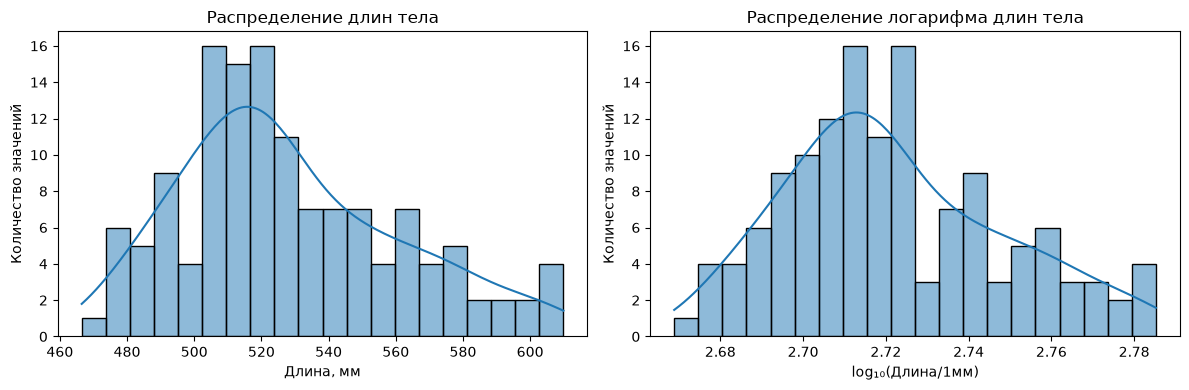

In [100]:
import numpy as np
import matplotlib.pyplot as plt

b_length = complete["C-R curved"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x=b_length, bins=20, kde=True,edgecolor="black", ax=axes[0])
axes[0].set_title("Распределение длин тела")
axes[0].set_xlabel("Длина, мм")
axes[0].set_ylabel("Количество значений")
sns.histplot(x=np.log10(b_length), bins=20, kde=True,edgecolor="black", ax=axes[1])
axes[1].set_title("Распределение логарифма длин тела")
axes[1].set_xlabel("log₁₀(Длина/1мм)")
axes[1].set_ylabel("Количество значений")
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
plt.tight_layout()
plt.show()

Подтвержение распределения длин тел по Фишеру с помощью Q-Q-графика.

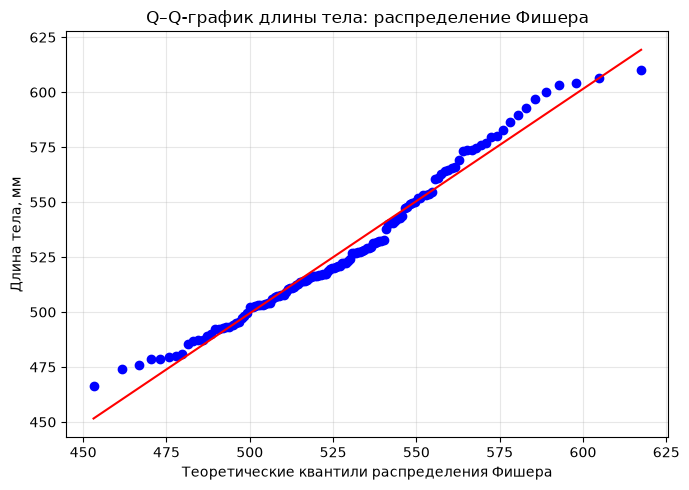

In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

b_length = pd.to_numeric(selected["C-R curved"].astype(str).str.replace(",", ".", regex=False),errors="coerce").dropna()
params = stats.f.fit(b_length, floc=0)
fig, ax = plt.subplots(figsize=(7, 5))
stats.probplot(b_length, dist=stats.f, sparams=params, plot=ax)
ax.set_title("Q–Q-график длины тела: распределение Фишера")
ax.set_xlabel("Теоретические квантили распределения Фишера")
ax.set_ylabel("Длина тела, мм")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Построение графиков функции распределения длины тел

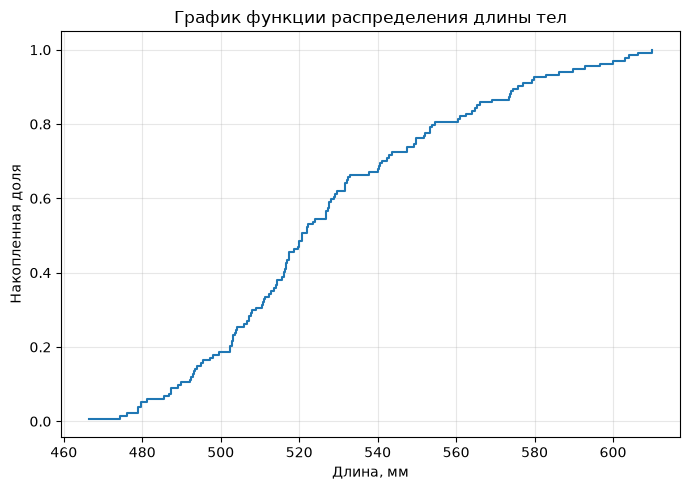

In [103]:
b_length_table = b_length_table.sort_values("b_length_mm")
b_length_table["P"] = b_length_table["p_i"].cumsum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.step(b_length_table["b_length_mm"], b_length_table["P"], where="post")
ax.set_title("График функции распределения длины тел")
ax.set_xlabel("Длина, мм")
ax.set_ylabel("Накопленная доля")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Вычисление разных статистик длин тел (математического ожидания, среднего, дисперсии, стандратного отклонения, моды и тд)

$$
\mu_Y=E[Y]=\sum_{i=1}^{k}y_i p_i, \qquad
D(Y)=\sum_{i=1}^{k}(y_i-\mu_Y)^2p_i,
\qquad \sigma_Y=\sqrt{D(Y)}.
$$

In [104]:
expected_b_length = (b_length_table["b_length_mm"] * b_length_table["p_i"]).sum()
variance_b_length = ((b_length_table["b_length_mm"] - b_length.mean()) ** 2* b_length_table["p_i"]).sum()
std_b_length = np.sqrt(variance_b_length)
modes_b_length = b_length.mode()
max_count = b_length.value_counts().max()
print(f"Мат. ожидание по таблице частот, мм: {expected_b_length:,.2f}")
print(f"Количество длин тел: {b_length.count():,.2f}")
print(f"Сумма длин тел, мм: {b_length.sum():.2f}")
print(f"Средняя длина тел, мм: {b_length.mean():,.2f}")
print(f"Медиана длин тел, мм: {b_length.median():,.2f}")
print(f"Минимальная длина тел, мм: {b_length.min():,.2f}")
print(f"Максимальная длина тел, мм: {b_length.max():,.2f}")
print(f"Cтандартное отклонение, мм: {b_length.std(ddof=0):,.2f}")
print(f"Первый квартиль (25%), мм: {b_length.quantile(0.25):,.2f}")
print(f"Третий квартиль (75%), мм: {b_length.quantile(0.75):,.2f}")
print(f"95-й перцентиль, мм: {b_length.quantile(0.95):,.2f}")
print(f"Дисперсия, мм²: {variance_b_length:,.2f}")
print(f"Стандартное отклонение, мм: {std_b_length:,.2f}")
print("Мода, мм:", modes_b_length.tolist())
print("Число повторений каждой моды:", max_count)

Мат. ожидание по таблице частот, мм: 528.11
Количество длин тел: 134.00
Сумма длин тел, мм: 70766.60
Средняя длина тел, мм: 528.11
Медиана длин тел, мм: 520.80
Минимальная длина тел, мм: 466.50
Максимальная длина тел, мм: 609.90
Cтандартное отклонение, мм: 32.43
Первый квартиль (25%), мм: 504.55
Третий квартиль (75%), мм: 549.67
95-й перцентиль, мм: 590.88
Дисперсия, мм²: 1,051.61
Стандартное отклонение, мм: 32.43
Мода, мм: [478.8, 502.4, 520.8, 522.1, 526.8, 531.6]
Число повторений каждой моды: 2


### Independence & Estimations

#### Состоятельность оценки

In [105]:
rng = np.random.default_rng(42)
population = complete["C-R curved"].to_numpy()
true_mean = population.mean()
sample_sizes = [10, 30, 100, 300, 1000, 3000]
repeats = 100
results = []
for n in sample_sizes:
    samples = rng.choice(population, size=(repeats, n), replace=True)
    estimates = samples.mean(axis=1)
    errors = estimates - true_mean
    results.append({
        "Размер выборки": n,
        "Среднее оценок, мм": estimates.mean(),
        "RMSE, мм": np.sqrt(np.mean(errors ** 2)),
        "Нижняя граница 95% оценок, мм": np.quantile(estimates, 0.025),
        "Верхняя граница 95% оценок, мм": np.quantile(estimates, 0.975)
    })
consistency_b_length = pd.DataFrame(results)
print(f"Средняя длина тела в генеральной совокупности: "f"{true_mean:.2f} мм")
display(consistency_b_length)

Средняя длина тела в генеральной совокупности: 528.11 мм


,Размер выборки,"Среднее оценок, мм","RMSE, мм","Нижняя граница 95% оценок, мм","Верхняя граница 95% оценок, мм"
0,10,528.486300,9.522300,512.620000,547.714000
1,30,527.863400,6.009465,517.958417,538.906333
2,100,527.428190,3.269179,521.371325,534.238525
3,300,528.173167,1.824406,525.061217,531.910658
4,1000,528.060596,1.239806,525.364230,530.738010
5,3000,528.177056,0.574058,527.118806,529.282688


#### Ошибка оценки среднего от размера выборки

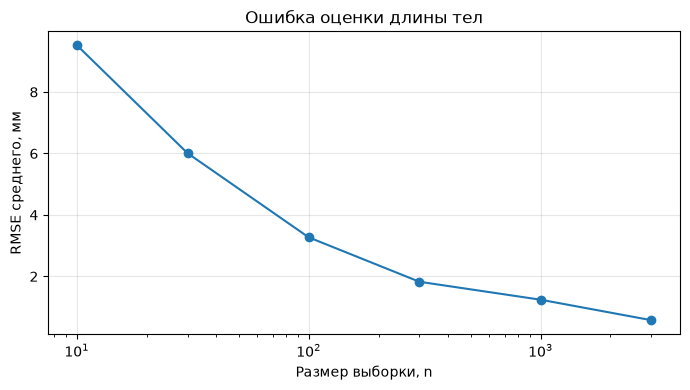

In [106]:
plt.figure(figsize=(7, 4))
plt.plot(consistency_b_length["Размер выборки"], consistency_b_length["RMSE, мм"], marker="o")
plt.xscale("log")
plt.xlabel("Размер выборки, n")
plt.ylabel("RMSE среднего, мм")
plt.title("Ошибка оценки длины тел")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Вычисление разных статистик длин тел в выборке с возвращением

In [107]:
b_with = sample_with["C-R curved"]
print("Количество:", b_with.count())
print(f"Среднее, мм: {b_with.mean():.2f}")
print(f"Медиана, мм: {b_with.median():.2f}")
print(f"Минимум, мм: {b_with.min():.2f}")
print(f"Максимум, мм: {b_with.max():.2f}")
print(f"Стандартное отклонение, мм: {b_with.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {b_with.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {b_with.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {b_with.quantile(0.95):.2f}")

Количество: 50
Среднее, мм: 531.46
Медиана, мм: 518.75
Минимум, мм: 479.80
Максимум, мм: 609.90
Стандартное отклонение, мм: 32.52
Первый квартиль, мм: 508.67
Третий квартиль, мм: 559.33
95-й перцентиль, мм: 591.50


#### Вычисление разных статистик длин тел в выборке без возвращения

In [108]:
b_without = sample_without["C-R curved"]
print("Количество:", b_without.count())
print(f"Среднее, мм: {b_without.mean():.2f}")
print(f"Медиана, мм: {b_without.median():.2f}")
print(f"Минимум, мм: {b_without.min():.2f}")
print(f"Максимум, мм: {b_without.max():.2f}")
print(f"Стандартное отклонение, мм: {b_without.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {b_without.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {b_without.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {b_without.quantile(0.95):.2f}")

Количество: 50
Среднее, мм: 523.53
Медиана, мм: 518.00
Минимум, мм: 466.50
Максимум, мм: 606.30
Стандартное отклонение, мм: 30.57
Первый квартиль, мм: 502.88
Третий квартиль, мм: 536.35
95-й перцентиль, мм: 592.26


Средняя длина тела, медиана и стандартное отклонение в выборке с возвращением были ближе к генеральной совокупности, чем без возвращения.

#### Вычисление разных статистик длин тел в выборке самцов

In [109]:
b_males = sample_males["C-R curved"]
print("Количество:", b_males.count())
print(f"Среднее, мм: {b_males.mean():.2f}")
print(f"Медиана, мм: {b_males.median():.2f}")
print(f"Минимум, мм: {b_males.min():.2f}")
print(f"Максимум, мм: {b_males.max():.2f}")
print(f"Стандартное отклонение, мм: {b_males.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {b_males.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {b_males.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {b_males.quantile(0.95):.2f}")

Количество: 42
Среднее, мм: 560.87
Медиана, мм: 563.30
Минимум, мм: 511.00
Максимум, мм: 609.90
Стандартное отклонение, мм: 27.64
Первый квартиль, мм: 541.23
Третий квартиль, мм: 579.17
95-й перцентиль, мм: 603.96


#### Вычисление разных статистик длин тел в выборке самок

In [110]:
b_females = sample_females["C-R curved"]
print("Количество:", b_females.count())
print(f"Среднее, мм: {b_females.mean():.2f}")
print(f"Медиана, мм: {b_females.median():.2f}")
print(f"Минимум, мм: {b_females.min():.2f}")
print(f"Максимум, мм: {b_females.max():.2f}")
print(f"Стандартное отклонение, мм: {b_females.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {b_females.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {b_females.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {b_females.quantile(0.95):.2f}")

Количество: 92
Среднее, мм: 513.15
Медиана, мм: 514.00
Минимум, мм: 466.50
Максимум, мм: 579.40
Стандартное отклонение, мм: 21.66
Первый квартиль, мм: 497.88
Третий квартиль, мм: 526.82
95-й перцентиль, мм: 549.52


#### Сравнение средних генеральной совокупности, выборки с и без возвращения

In [111]:
print(f"Среднее генеральной совокупности, мм: {b_length.mean():.2f}")
print(f"Среднее выборки с возвращением, мм: {b_with.mean():.2f}")
print(f"Среднее выборки без возвращения, мм: {b_without.mean():.2f}")
print(f"Ошибка среднего с возвращением, %: {abs(b_with.mean() - b_length.mean()) / b_length.mean() * 100:.2f}")
print(f"Ошибка среднего без возвращения, %: {abs(b_without.mean() - b_length.mean()) / b_length.mean() * 100:.2f}")

Среднее генеральной совокупности, мм: 528.11
Среднее выборки с возвращением, мм: 531.46
Среднее выборки без возвращения, мм: 523.53
Ошибка среднего с возвращением, %: 0.64
Ошибка среднего без возвращения, %: 0.87


#### Сравнение средней длины тела самок и самцов

In [112]:
difference = b_males.mean() - b_females.mean()
relative_difference = difference / b_females.mean() * 100
print(f"Среднее всей совокупности, мм: {b_length.mean():.2f}")
print(f"Среднее самцов, мм: {b_males.mean():.2f}")
print(f"Среднее самок, мм: {b_females.mean():.2f}")
print(f"Разность средних «самцы − самки», мм: {difference:.2f}")
print(f"Средняя длина самцов выше средней длины самок на {relative_difference:.2f}%")

Среднее всей совокупности, мм: 528.11
Среднее самцов, мм: 560.87
Среднее самок, мм: 513.15
Разность средних «самцы − самки», мм: 47.72
Средняя длина самцов выше средней длины самок на 9.30%


Средняя длина тела в генеральной совокупности составляет 528.11 мм. В выборке с возвращением она равна 531.46 мм — завышение на 0.64%, а без возвращения — 523.53 мм, занижение на 0.87%. Медиана в выборке с возвращением (518.75 мм) была ближе к медиане и генеральной выборки (520.80 мм), чем медиана без возвращения (518.0 мм). Стандартное отклонение с возвращения (32.52 мм) было ближе к стандартному отклонению генеральной выборки (32.43 мм), чем стандартное отклонение без возвращением (30.57 мм).

Длина тела зависит от пола: самцы длинее самок на 47.72 мм или на 9.3%.

<a id="humerus"></a>
## Random Variable Humerus Length

### Description (природа события)

Случайная величина (Z) - длина плечевой кости животного в выбранной строке с единицей измерения [мм].
Только после выбора строки можно узнать длину плечевой кости, то есть величина заранее не известна. Но каждой конкретной строке соответствует одна длина. Это соответствует определению случайной величины у Н.Ш.Кремера (стр.89-90).

$$
Z(\omega_j) = h_j
$$

### EDA & Distribution

До случайного выбора животного неизвестно, какое значение примет (Z).

$$
P(Z=z_i)=p_i=\frac{n_i}{N}, \qquad
p_i \geq 0, \qquad \sum_{i=1}^{k}p_i=1.
$$

#### Была построена гистограмма распределения длин плечевых костей животных.

Распределение в исходной гистограмме длин плечевых костей животных визуально не является нормальным, поэтому длины были прологарифмированы (взят десятичный логарифм). Распределение на логарифмируемом графике визуально не похоже на нормальное. Сделано предположение, что это распределение Фишера.

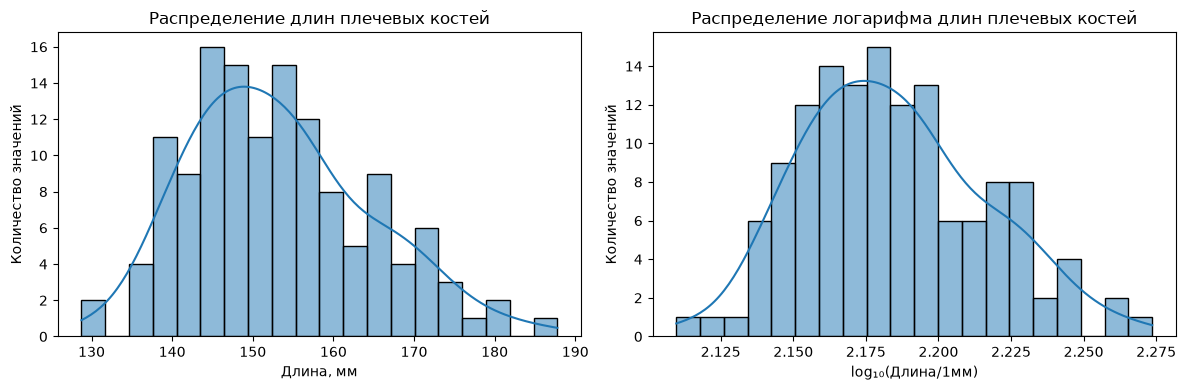

In [113]:
import numpy as np
import matplotlib.pyplot as plt

h_length = complete["R humeral max"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x=h_length, bins=20, kde=True,edgecolor="black", ax=axes[0])
axes[0].set_title("Распределение длин плечевых костей")
axes[0].set_xlabel("Длина, мм")
axes[0].set_ylabel("Количество значений")
sns.histplot(x=np.log10(h_length), bins=20, kde=True,edgecolor="black", ax=axes[1])
axes[1].set_title("Распределение логарифма длин плечевых костей")
axes[1].set_xlabel("log₁₀(Длина/1мм)")
axes[1].set_ylabel("Количество значений")
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
plt.tight_layout()
plt.show()

Подтвержение распределения длин плечевых костей по Фишеру с помощью Q-Q-графика.

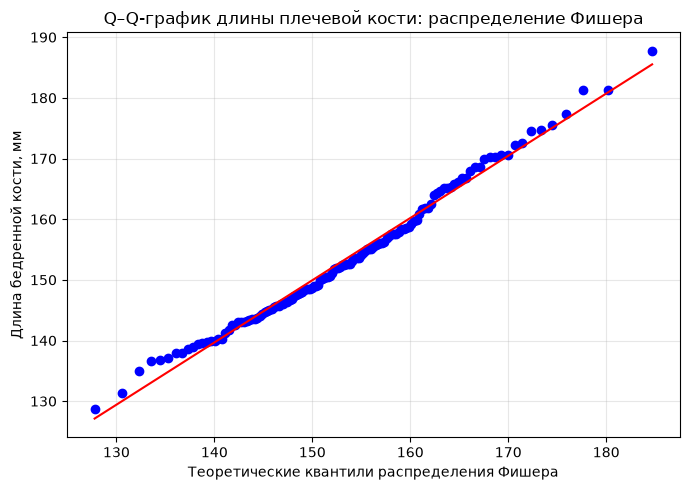

In [114]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

h_length = pd.to_numeric(selected["R humeral max"].astype(str).str.replace(",", ".", regex=False),errors="coerce").dropna()
params = stats.f.fit(h_length, floc=0)
fig, ax = plt.subplots(figsize=(7, 5))
stats.probplot(h_length, dist=stats.f, sparams=params, plot=ax)
ax.set_title("Q–Q-график длины плечевой кости: распределение Фишера")
ax.set_xlabel("Теоретические квантили распределения Фишера")
ax.set_ylabel("Длина бедренной кости, мм")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Построение графиков функции распределения длины плечевых костей

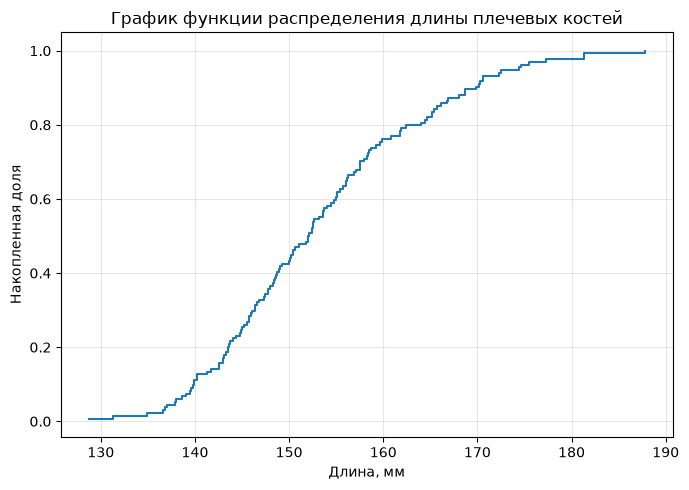

In [116]:
h_length_table = h_length_table.sort_values("h_length_mm")
h_length_table["P"] = h_length_table["p_i"].cumsum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.step(h_length_table["h_length_mm"], h_length_table["P"], where="post")
ax.set_title("График функции распределения длины плечевых костей")
ax.set_xlabel("Длина, мм")
ax.set_ylabel("Накопленная доля")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Вычисление разных статистик длин плечевых костей (математического ожидания, среднего, дисперсии, стандратного отклонения, моды и тд)

$$
\mu_Z=E[Z]=\sum_{i=1}^{k}z_i p_i, \qquad
D(Z)=\sum_{i=1}^{k}(z_i-\mu_Z)^2p_i,
\qquad \sigma_Z=\sqrt{D(Z)}.
$$

In [117]:
expected_h_length = (h_length_table["h_length_mm"] * h_length_table["p_i"]).sum()
variance_h_length = ((h_length_table["h_length_mm"] - h_length.mean()) ** 2* h_length_table["p_i"]).sum()
std_h_length = np.sqrt(variance_h_length)
modes_h_length = h_length.mode()
max_count = h_length.value_counts().max()
print(f"Мат. ожидание по таблице частот, мм: {expected_h_length:,.2f}")
print(f"Количество длин плечевых костей: {h_length.count():,.2f}")
print(f"Сумма длин плечевых костей, мм: {h_length.sum():.2f}")
print(f"Средняя длина плечевых костей, мм: {h_length.mean():,.2f}")
print(f"Медиана длин плечевых костей, мм: {h_length.median():,.2f}")
print(f"Минимальная длина плечевых костей, мм: {h_length.min():,.2f}")
print(f"Максимальная длина плечевых костей, мм: {h_length.max():,.2f}")
print(f"Cтандартное отклонение, мм: {h_length.std(ddof=0):,.2f}")
print(f"Первый квартиль (25%), мм: {h_length.quantile(0.25):,.2f}")
print(f"Третий квартиль (75%), мм: {h_length.quantile(0.75):,.2f}")
print(f"95-й перцентиль, мм: {h_length.quantile(0.95):,.2f}")
print(f"Дисперсия, мм²: {variance_h_length:,.2f}")
print(f"Стандартное отклонение, мм: {std_h_length:,.2f}")
print("Мода, мм:", modes_h_length.tolist())
print("Число повторений каждой моды:", max_count)

Мат. ожидание по таблице частот, мм: 153.28
Количество длин плечевых костей: 134.00
Сумма длин плечевых костей, мм: 20539.77
Средняя длина плечевых костей, мм: 153.28
Медиана длин плечевых костей, мм: 152.06
Минимальная длина плечевых костей, мм: 128.74
Максимальная длина плечевых костей, мм: 187.77
Cтандартное отклонение, мм: 11.20
Первый квартиль (25%), мм: 145.03
Третий квартиль (75%), мм: 159.55
95-й перцентиль, мм: 173.21
Дисперсия, мм²: 125.50
Стандартное отклонение, мм: 11.20
Мода, мм: [140.26, 168.63]
Число повторений каждой моды: 2


### Independence & Estimations

#### Состоятельность оценки

In [118]:
rng = np.random.default_rng(42)
population = complete["R humeral max"].to_numpy()
true_mean = population.mean()
sample_sizes = [10, 30, 100, 300, 1000, 3000]
repeats = 100
results = []
for n in sample_sizes:
    samples = rng.choice(population, size=(repeats, n), replace=True)
    estimates = samples.mean(axis=1)
    errors = estimates - true_mean
    results.append({
        "Размер выборки": n,
        "Среднее оценок, мм": estimates.mean(),
        "RMSE, мм": np.sqrt(np.mean(errors ** 2)),
        "Нижняя граница 95% оценок, мм": np.quantile(estimates, 0.025),
        "Верхняя граница 95% оценок, мм": np.quantile(estimates, 0.975)
    })
consistency_h_length = pd.DataFrame(results)
print(f"Средняя длина плечевой кости в генеральной совокупности: "f"{true_mean:.2f} мм")
display(consistency_h_length)

Средняя длина плечевой кости в генеральной совокупности: 153.28 мм


,Размер выборки,"Среднее оценок, мм","RMSE, мм","Нижняя граница 95% оценок, мм","Верхняя граница 95% оценок, мм"
0,10,153.565290,3.349257,148.197475,160.676275
1,30,153.243443,2.181353,148.797675,156.862083
2,100,153.117538,1.047673,151.217552,155.208265
3,300,153.204437,0.527346,152.211446,154.098032
4,1000,153.259727,0.389991,152.635264,154.022905
5,3000,153.297925,0.210949,152.925137,153.672551


#### Ошибка оценки среднего от размера выборки

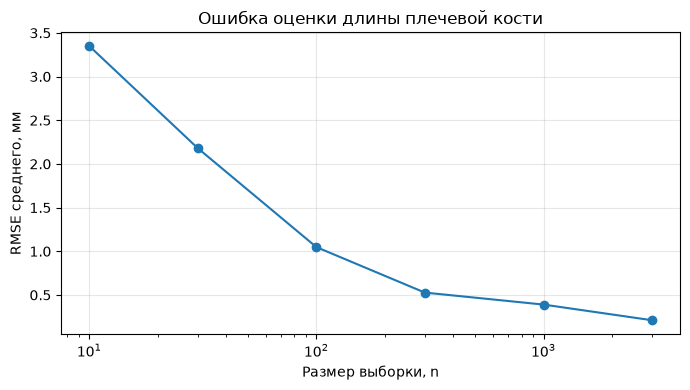

In [119]:
plt.figure(figsize=(7, 4))
plt.plot(consistency_h_length["Размер выборки"], consistency_h_length["RMSE, мм"], marker="o")
plt.xscale("log")
plt.xlabel("Размер выборки, n")
plt.ylabel("RMSE среднего, мм")
plt.title("Ошибка оценки длины плечевой кости")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Вычисление разных статистик длин плечевых костей в выборке с возвращением

In [120]:
h_with = sample_with["R humeral max"]
print("Количество:", h_with.count())
print(f"Среднее, мм: {h_with.mean():.2f}")
print(f"Медиана, мм: {h_with.median():.2f}")
print(f"Минимум, мм: {h_with.min():.2f}")
print(f"Максимум, мм: {h_with.max():.2f}")
print(f"Стандартное отклонение, мм: {h_with.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {h_with.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {h_with.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {h_with.quantile(0.95):.2f}")

Количество: 50
Среднее, мм: 154.21
Медиана, мм: 153.07
Минимум, мм: 128.74
Максимум, мм: 181.37
Стандартное отклонение, мм: 11.78
Первый квартиль, мм: 145.11
Третий квартиль, мм: 161.20
95-й перцентиль, мм: 176.48


#### Вычисление разных статистик длин плечевых костей в выборке без возвращения

In [121]:
h_without = sample_without["R humeral max"]
print("Количество:", h_without.count())
print(f"Среднее, мм: {h_without.mean():.2f}")
print(f"Медиана, мм: {h_without.median():.2f}")
print(f"Минимум, мм: {h_without.min():.2f}")
print(f"Максимум, мм: {h_without.max():.2f}")
print(f"Стандартное отклонение, мм: {h_without.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {h_without.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {h_without.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {h_without.quantile(0.95):.2f}")

Количество: 50
Среднее, мм: 151.67
Медиана, мм: 152.25
Минимум, мм: 134.94
Максимум, мм: 187.77
Стандартное отклонение, мм: 10.05
Первый квартиль, мм: 144.88
Третий квартиль, мм: 156.19
95-й перцентиль, мм: 168.68


Средняя длина плечевой кости, медиана и стандартное отклонение в выборке с возвращением были ближе к генеральной совокупности, чем без возвращения.

#### Вычисление разных статистик длин плечевых костей в выборке самцов

In [122]:
h_males = sample_males["R humeral max"]
print("Количество:", h_males.count())
print(f"Среднее, мм: {h_males.mean():.2f}")
print(f"Медиана, мм: {h_males.median():.2f}")
print(f"Минимум, мм: {h_males.min():.2f}")
print(f"Максимум, мм: {h_males.max():.2f}")
print(f"Стандартное отклонение, мм: {h_males.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {h_males.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {h_males.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {h_males.quantile(0.95):.2f}")

Количество: 42
Среднее, мм: 166.36
Медиана, мм: 165.56
Минимум, мм: 154.73
Максимум, мм: 187.77
Стандартное отклонение, мм: 7.62
Первый квартиль, мм: 161.06
Третий квартиль, мм: 170.49
95-й перцентиль, мм: 181.14


#### Вычисление разных статистик длин плечевых костей в выборке самок

In [123]:
h_females = sample_females["R humeral max"]
print("Количество:", h_females.count())
print(f"Среднее, мм: {h_females.mean():.2f}")
print(f"Медиана, мм: {h_females.median():.2f}")
print(f"Минимум, мм: {h_females.min():.2f}")
print(f"Максимум, мм: {h_females.max():.2f}")
print(f"Стандартное отклонение, мм: {h_females.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {h_females.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {h_females.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {h_females.quantile(0.95):.2f}")

Количество: 92
Среднее, мм: 147.31
Медиана, мм: 147.61
Минимум, мм: 128.74
Максимум, мм: 159.84
Стандартное отклонение, мм: 6.53
Первый квартиль, мм: 143.08
Третий квартиль, мм: 152.39
95-й перцентиль, мм: 157.67


#### Сравнение средних генеральной совокупности, выборки с и без возвращения

In [124]:
print(f"Среднее генеральной совокупности, мм: {h_length.mean():.2f}")
print(f"Среднее выборки с возвращением, мм: {h_with.mean():.2f}")
print(f"Среднее выборки без возвращения, мм: {h_without.mean():.2f}")
print(f"Ошибка среднего с возвращением, %: {abs(h_with.mean() - h_length.mean()) / h_length.mean() * 100:.2f}")
print(f"Ошибка среднего без возвращения, %: {abs(h_without.mean() - h_length.mean()) / h_length.mean() * 100:.2f}")

Среднее генеральной совокупности, мм: 153.28
Среднее выборки с возвращением, мм: 154.21
Среднее выборки без возвращения, мм: 151.67
Ошибка среднего с возвращением, %: 0.60
Ошибка среднего без возвращения, %: 1.05


#### Сравнение средней длины плечевой кости самок и самцов

In [125]:
difference = h_males.mean() - h_females.mean()
relative_difference = difference / h_females.mean() * 100
print(f"Среднее всей совокупности, мм: {h_length.mean():.2f}")
print(f"Среднее самцов, мм: {h_males.mean():.2f}")
print(f"Среднее самок, мм: {h_females.mean():.2f}")
print(f"Разность средних «самцы − самки», мм: {difference:.2f}")
print(f"Средняя длина плечевых костей самцов выше средней длины плечевых костей самок на {relative_difference:.2f}%")

Среднее всей совокупности, мм: 153.28
Среднее самцов, мм: 166.36
Среднее самок, мм: 147.31
Разность средних «самцы − самки», мм: 19.04
Средняя длина плечевых костей самцов выше средней длины плечевых костей самок на 12.93%


Средняя длина плечевой кости в генеральной совокупности составляет 153.28 мм. В выборке с возвращением она равна 154.21 мм — завышение на 0.60%, а без возвращения — 151.67 мм, занижение на 1.05%. Медиана в выборке с возвращением (153.07 мм) была ближе к медиане и генеральной выборки (152.06 мм), чем медиана без возвращения (152.25 мм). Стандартное отклонение с возвращения (11.78 мм) было ближе к стандартному отклонению генеральной выборки (11.20 мм), чем стандартное отклонение без возвращением (10.05 мм).

Длина плечевых костей зависит от пола: кости самцов длинее самок на 19.04 мм или на 12.93%.

<a id="femur"></a>
## Random Variable Femural Length

### Description (природа события)

Случайная величина (Z) - длина бедренной кости животного в выбранной строке с единицей измерения [мм].
Только после выбора строки можно узнать длину бедренной кости, то есть величина заранее не известна. Но каждой конкретной строке соответствует одна длина. Это соответствует определению случайной величины у Н.Ш.Кремера (стр.89-90). До случайного выбора животного неизвестно, какое значение примет (W).

$$
W(\omega_j) = f_j
$$

### EDA & Distribution

$$
P(W=w_i)=p_i=\frac{n_i}{N}, \qquad
p_i \geq 0, \qquad \sum_{i=1}^{k}p_i=1.
$$

#### Была построена гистограмма распределения длин бедренных костей животных.

Распределение в исходной гистограмме длин бедренных костей животных визуально не является нормальным, поэтому длины были прологарифмированы (взят десятичный логарифм). Распределение на логарифмируемом графике визуально не похоже на нормальное. Сделано предположение, что это распределение Фишера.

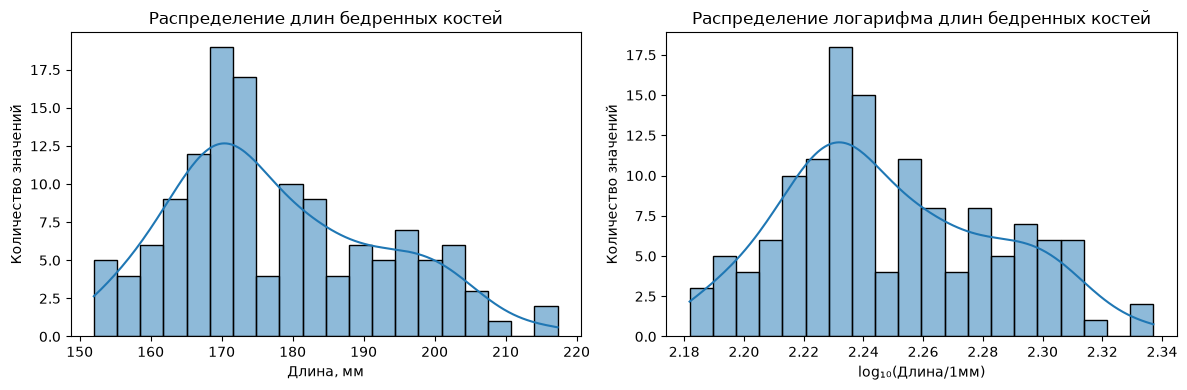

In [126]:
import numpy as np
import matplotlib.pyplot as plt

f_length = complete["R femoral max"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x=f_length, bins=20, kde=True,edgecolor="black", ax=axes[0])
axes[0].set_title("Распределение длин бедренных костей")
axes[0].set_xlabel("Длина, мм")
axes[0].set_ylabel("Количество значений")
sns.histplot(x=np.log10(f_length), bins=20, kde=True,edgecolor="black", ax=axes[1])
axes[1].set_title("Распределение логарифма длин бедренных костей")
axes[1].set_xlabel("log₁₀(Длина/1мм)")
axes[1].set_ylabel("Количество значений")
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
plt.tight_layout()
plt.show()

Подтвержение распределения длин бедренных костей по Фишеру с помощью Q-Q-графика.

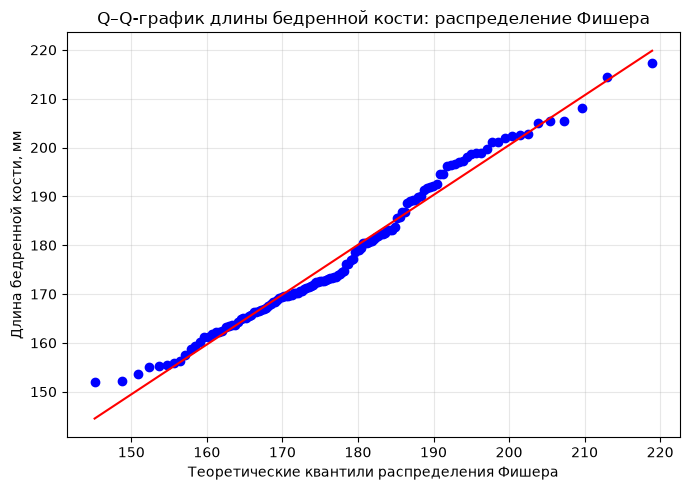

In [127]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

f_length = pd.to_numeric(selected["R femoral max"].astype(str).str.replace(",", ".", regex=False),errors="coerce").dropna()
params = stats.f.fit(f_length, floc=0)
fig, ax = plt.subplots(figsize=(7, 5))
stats.probplot(f_length, dist=stats.f, sparams=params, plot=ax)
ax.set_title("Q–Q-график длины бедренной кости: распределение Фишера")
ax.set_xlabel("Теоретические квантили распределения Фишера")
ax.set_ylabel("Длина бедренной кости, мм")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Построение графиков функции распределения длины бедренных костей

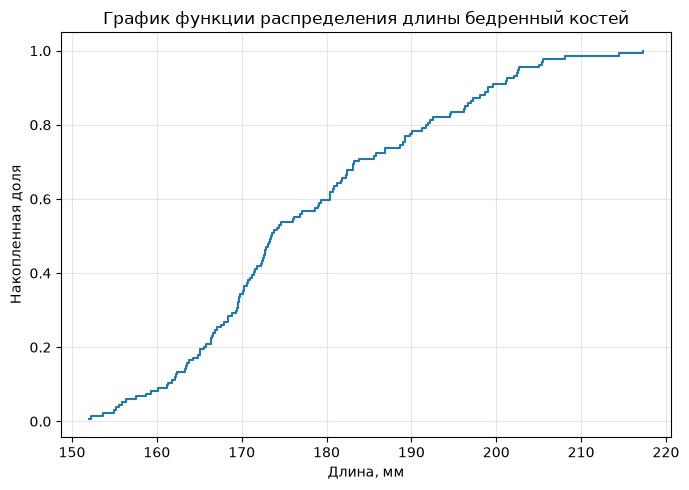

In [129]:
f_length_table = f_length_table.sort_values("f_length_mm")
f_length_table["P"] = f_length_table["p_i"].cumsum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.step(f_length_table["f_length_mm"], f_length_table["P"], where="post")
ax.set_title("График функции распределения длины бедренный костей")
ax.set_xlabel("Длина, мм")
ax.set_ylabel("Накопленная доля")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Вычисление разных статистик длин бедренных костей (математического ожидания, среднего, дисперсии, стандратного отклонения, моды и тд)

$$
\mu_W=E[W]=\sum_{i=1}^{k}w_i p_i, \qquad
D(W)=\sum_{i=1}^{k}(w_i-\mu_W)^2p_i,
\qquad \sigma_W=\sqrt{D(W)}.
$$

In [130]:
expected_f_length = (f_length_table["f_length_mm"] * f_length_table["p_i"]).sum()
variance_f_length = ((f_length_table["f_length_mm"] - f_length.mean()) ** 2* f_length_table["p_i"]).sum()
std_f_length = np.sqrt(variance_f_length)
modes_f_length = f_length.mode()
max_count = f_length.value_counts().max()
print(f"Мат. ожидание по таблице частот, мм: {expected_f_length:,.2f}")
print(f"Сумма длин бедренных костей, мм: {f_length.sum():.2f}")
print(f"Средняя длина бедренных костей, мм: {f_length.mean():,.2f}")
print(f"Медиана длин бедренных костей, мм: {f_length.median():,.2f}")
print(f"Минимальная длина бедренных костей, мм: {f_length.min():,.2f}")
print(f"Максимальная длина бедренных костей, мм: {f_length.max():,.2f}")
print(f"Cтандартное отклонение, мм: {f_length.std(ddof=0):,.2f}")
print(f"Первый квартиль (25%), мм: {f_length.quantile(0.25):,.2f}")
print(f"Третий квартиль (75%), мм: {f_length.quantile(0.75):,.2f}")
print(f"95-й перцентиль, мм: {f_length.quantile(0.95):,.2f}")
print(f"Дисперсия, мм²: {variance_f_length:,.2f}")
print(f"Стандартное отклонение, мм: {std_f_length:,.2f}")
print("Мода, мм:", modes_f_length.tolist())
print("Число повторений каждой моды:", max_count)

Мат. ожидание по таблице частот, мм: 177.78
Сумма длин бедренных костей, мм: 23822.72
Средняя длина бедренных костей, мм: 177.78
Медиана длин бедренных костей, мм: 173.51
Минимальная длина бедренных костей, мм: 151.99
Максимальная длина бедренных костей, мм: 217.33
Cтандартное отклонение, мм: 14.50
Первый квартиль (25%), мм: 167.23
Третий квартиль (75%), мм: 188.97
95-й перцентиль, мм: 202.63
Дисперсия, мм²: 210.28
Стандартное отклонение, мм: 14.50
Мода, мм: [168.4, 180.45, 198.98]
Число повторений каждой моды: 2


### Independence & Estimations

#### Состоятельность оценки

In [131]:
rng = np.random.default_rng(42)
population = complete["R femoral max"].to_numpy()
true_mean = population.mean()
sample_sizes = [10, 30, 100, 300, 1000, 3000]
repeats = 1000
results = []
for n in sample_sizes:
    samples = rng.choice(population, size=(repeats, n), replace=True)
    estimates = samples.mean(axis=1)
    errors = estimates - true_mean
    results.append({
        "Размер выборки": n,
        "Среднее оценок, мм": estimates.mean(),
        "RMSE, мм": np.sqrt(np.mean(errors ** 2)),
        "Нижняя граница 95% оценок, мм": np.quantile(estimates, 0.025),
        "Верхняя граница 95% оценок, мм": np.quantile(estimates, 0.975)
    })
consistency_f_length = pd.DataFrame(results)
print(f"Средняя длина бедренной кости в генеральной совокупности: "f"{true_mean:.2f} мм")
display(consistency_f_length)

Средняя длина бедренной кости в генеральной совокупности: 177.78 мм


,Размер выборки,"Среднее оценок, мм","RMSE, мм","Нижняя граница 95% оценок, мм","Верхняя граница 95% оценок, мм"
0,10,177.683603,4.719891,169.108575,187.080375
1,30,177.657856,2.623208,172.673433,182.833158
2,100,177.758506,1.433534,174.780640,180.615217
3,300,177.796254,0.861866,176.072113,179.558403
4,1000,177.776169,0.454804,176.889205,178.649505
5,3000,177.771446,0.256152,177.262889,178.271903


#### Ошибка оценки среднего от размера выборки

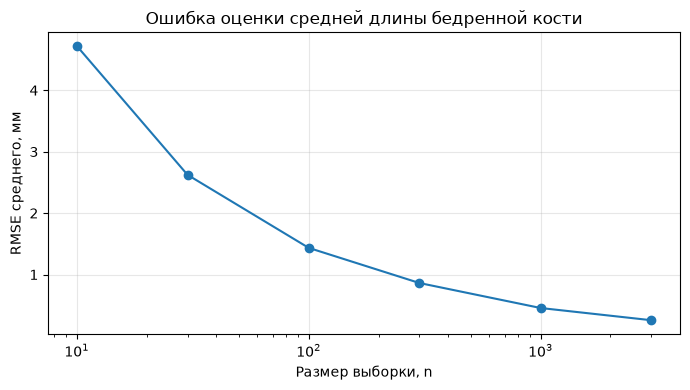

In [132]:
plt.figure(figsize=(7, 4))
plt.plot(consistency_f_length["Размер выборки"], consistency_f_length["RMSE, мм"], marker="o")
plt.xscale("log")
plt.xlabel("Размер выборки, n")
plt.ylabel("RMSE среднего, мм")
plt.title("Ошибка оценки средней длины бедренной кости")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Вычисление разных статистик длин бедренных костей в выборке с возвращением

In [133]:
f_with = sample_with["R femoral max"]
print("Количество:", f_with.count())
print(f"Среднее, мм: {f_with.mean():.2f}")
print(f"Медиана, мм: {f_with.median():.2f}")
print(f"Минимум, мм: {f_with.min():.2f}")
print(f"Максимум, мм: {f_with.max():.2f}")
print(f"Стандартное отклонение, мм: {f_with.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {f_with.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {f_with.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {f_with.quantile(0.95):.2f}")

Количество: 50
Среднее, мм: 178.25
Медиана, мм: 175.55
Минимум, мм: 154.97
Максимум, мм: 214.48
Стандартное отклонение, мм: 15.30
Первый квартиль, мм: 166.53
Третий квартиль, мм: 185.30
95-й перцентиль, мм: 204.04


#### Вычисление разных статистик длин бедренных костей в выборке без возвращения

In [134]:
f_without = sample_without["R femoral max"]
print("Количество:", f_without.count())
print(f"Среднее, мм: {f_without.mean():.2f}")
print(f"Медиана, мм: {f_without.median():.2f}")
print(f"Минимум, мм: {f_without.min():.2f}")
print(f"Максимум, мм: {f_without.max():.2f}")
print(f"Стандартное отклонение, мм: {f_without.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {f_without.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {f_without.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {f_without.quantile(0.95):.2f}")

Количество: 50
Среднее, мм: 175.43
Медиана, мм: 172.93
Минимум, мм: 151.99
Максимум, мм: 217.33
Стандартное отклонение, мм: 13.54
Первый квартиль, мм: 169.65
Третий квартиль, мм: 182.18
95-й перцентиль, мм: 200.06


Средняя длина бедренной кости, медиана и стандартное отклонение в выборке с возвращением были ближе к генеральной совокупности, чем без возвращения.

#### Вычисление разных статистик длин бедренных костей в выборке самцов

In [135]:
f_males = sample_males["R femoral max"]
print("Количество:", f_males.count())
print(f"Среднее, мм: {f_males.mean():.2f}")
print(f"Медиана, мм: {f_males.median():.2f}")
print(f"Минимум, мм: {f_males.min():.2f}")
print(f"Максимум, мм: {f_males.max():.2f}")
print(f"Стандартное отклонение, мм: {f_males.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {f_males.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {f_males.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {f_males.quantile(0.95):.2f}")

Количество: 42
Среднее, мм: 195.65
Медиана, мм: 196.27
Минимум, мм: 181.25
Максимум, мм: 217.33
Стандартное отклонение, мм: 8.26
Первый квартиль, мм: 189.35
Третий квартиль, мм: 201.18
95-й перцентиль, мм: 208.02


#### Вычисление разных статистик длин бедренных костей в выборке самок

In [136]:
f_females = sample_females["R femoral max"]
print("Количество:", f_females.count())
print(f"Среднее, мм: {f_females.mean():.2f}")
print(f"Медиана, мм: {f_females.median():.2f}")
print(f"Минимум, мм: {f_females.min():.2f}")
print(f"Максимум, мм: {f_females.max():.2f}")
print(f"Стандартное отклонение, мм: {f_females.std(ddof=0):.2f}")
print(f"Первый квартиль, мм: {f_females.quantile(0.25):.2f}")
print(f"Третий квартиль, мм: {f_females.quantile(0.75):.2f}")
print(f"95-й перцентиль, мм: {f_females.quantile(0.95):.2f}")

Количество: 92
Среднее, мм: 169.62
Медиана, мм: 170.01
Минимум, мм: 151.99
Максимум, мм: 189.30
Стандартное отклонение, мм: 7.93
Первый квартиль, мм: 164.67
Третий квартиль, мм: 173.93
95-й перцентиль, мм: 182.06


#### Сравнение средних генеральной совокупности, выборки с и без возвращения

In [137]:
print(f"Среднее генеральной совокупности, мм: {f_length.mean():.2f}")
print(f"Среднее выборки с возвращением, мм: {f_with.mean():.2f}")
print(f"Среднее выборки без возвращения, мм: {f_without.mean():.2f}")
print(f"Ошибка среднего с возвращением, %: {abs(f_with.mean() - f_length.mean()) / f_length.mean() * 100:.2f}")
print(f"Ошибка среднего без возвращения, %: {abs(f_without.mean() - f_length.mean()) / f_length.mean() * 100:.2f}")

Среднее генеральной совокупности, мм: 177.78
Среднее выборки с возвращением, мм: 178.25
Среднее выборки без возвращения, мм: 175.43
Ошибка среднего с возвращением, %: 0.26
Ошибка среднего без возвращения, %: 1.32


#### Сравнение средней длины бедренной кости самок и самцов

In [138]:
difference = f_males.mean() - f_females.mean()
relative_difference = difference / f_females.mean() * 100
print(f"Среднее всей совокупности, мм: {f_length.mean():.2f}")
print(f"Среднее самцов, мм: {f_males.mean():.2f}")
print(f"Среднее самок, мм: {f_females.mean():.2f}")
print(f"Разность средних «самцы − самки», мм: {difference:.2f}")
print(f"Средняя длина бедренных костей самцов выше средней длины бедренных костей самок на {relative_difference:.2f}%")

Среднее всей совокупности, мм: 177.78
Среднее самцов, мм: 195.65
Среднее самок, мм: 169.62
Разность средних «самцы − самки», мм: 26.02
Средняя длина бедренных костей самцов выше средней длины бедренных костей самок на 15.34%


Средняя длина бедренной кости в генеральной совокупности составляет 177.78 мм. В выборке с возвращением она равна 178.24 мм — завышение на 0.26%, а без возвращения — 175.43 мм, занижение на 1.32%. Медиана в выборке без возвращения (172.93 мм) была ближе к медиане и генеральной выборки (173.51 мм), чем медиана с возвращением (175.55 мм). Стандартное отклонение с возвращением (15.30 мм) было ближе к стандартному отклонению генеральной выборки (14.50 мм), чем стандартное отклонение без возвращения (13.54 мм).

Длина плечевых костей зависит от пола: кости самцов длинее самок на 26.02 мм или на 15.34%.

<a id="dependencies"></a>
## Выделение зависимостей

<a id="dependency-check"></a>
### Проверка зависимости
Если две случайные величины независимы, вероятность совместного выполнения двух условий равна произведению вероятностей каждого условия.

$$ \boxed{P(A\cap B)\stackrel{?}{=}P(A)\cdot P(B)} $$

In [153]:
dependent_pairs = []

for name, first, second in pairs:
    A = first <= first.median()
    B = second <= second.median()

    p_A = A.mean()
    p_B = B.mean()
    p_AB = (A & B).mean()

    if not np.isclose(p_AB, p_A * p_B):
        dependent_pairs.append(name)

print("Есть зависимости между:")
for name in dependent_pairs:
    print(name)

Есть зависимости между:
Масса и длина тела
Масса тела и длина плечевой кости
Масса тела и длина бедренной кости
Длина тела и длина плечевой кости
Длина тела и длина бедренной кости
Длина плечевой и длина бедренной костей
Масса тела и доля китайского происхождения
Длина тела и доля китайского происхождения
Длина плечевой кости и доля китайского происхождения
Длина бедренной кости и доля китайского происхождения


<a id="dependency-plots"></a>
### Графики величин

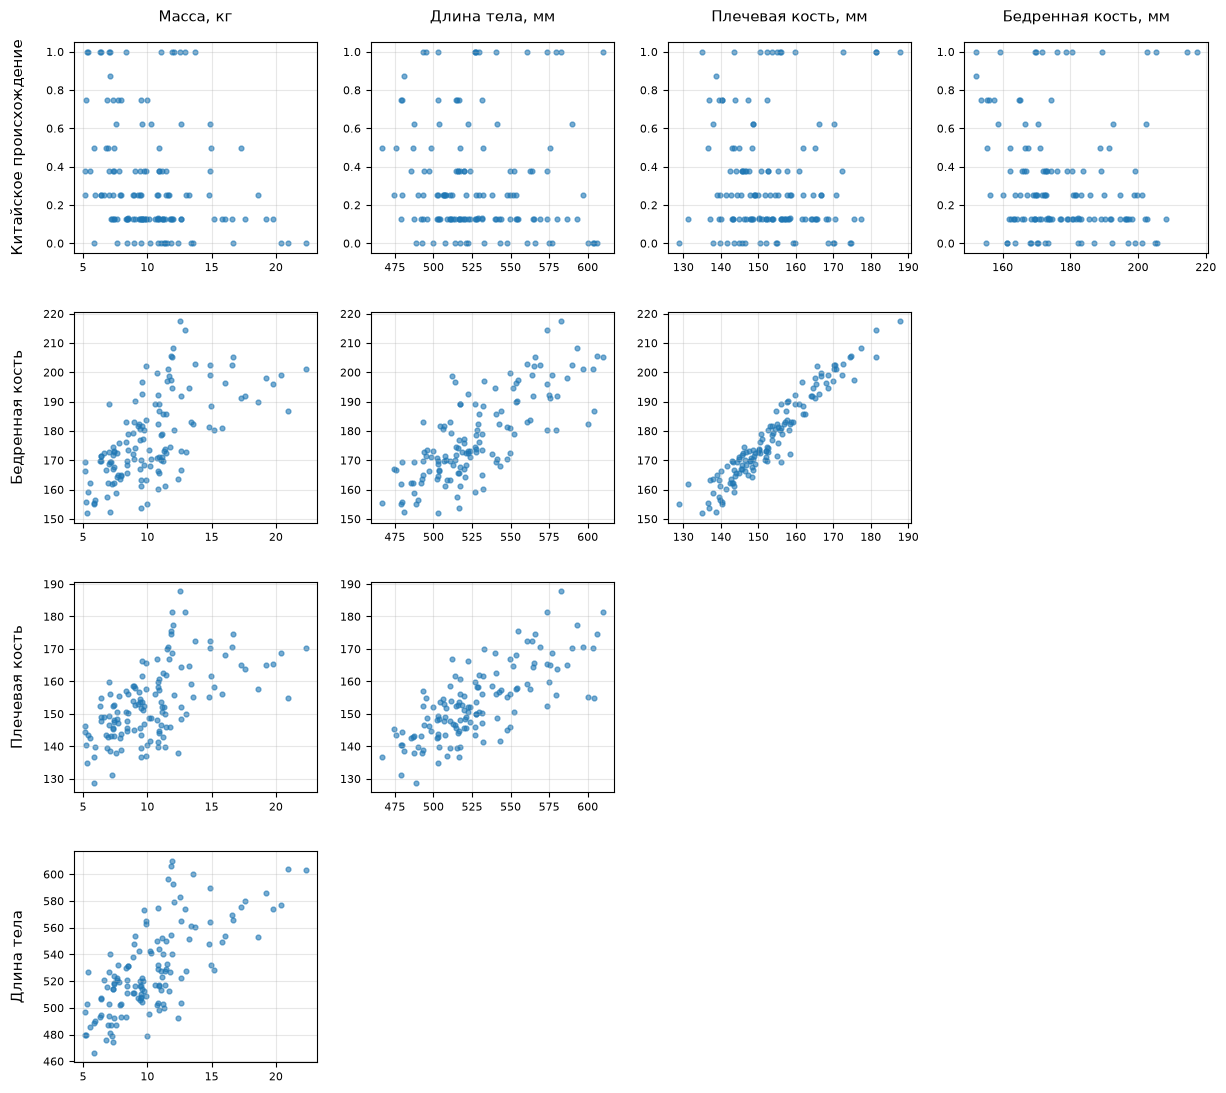

In [169]:
x_variables = {"Масса, кг": mass, "Длина тела, мм": b_length, "Плечевая кость, мм": h_length, "Бедренная кость, мм": f_length}
y_variables = {"Китайское происхождение": ancestry, "Бедренная кость": f_length, "Плечевая кость": h_length, "Длина тела": b_length}
x_names = list(x_variables.keys())
y_names = list(y_variables.keys())
x_values = list(x_variables.values())
y_values = list(y_variables.values())
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for i in range(4):
    for j in range(4):
        ax = axes[i, j]
        if j < 4 - i:
            ax.scatter(x_values[j], y_values[i], alpha=0.6, s=12)
            ax.grid(alpha=0.3)
            ax.tick_params(axis="both", labelsize=8)
        else:
            ax.axis("off")
fig.subplots_adjust(left=0.17, right=0.98, top=0.91, bottom=0.06, wspace=0.22, hspace=0.28)
for j in range(4):
    axes[0, j].set_title(x_names[j], fontsize=11, pad=15)
for i in range(4):
    pos = axes[i, 0].get_position()
    y_center = (pos.y0 + pos.y1) / 2
    fig.text(0.13, y_center, y_names[i], ha="center", va="center", rotation=90, fontsize=11)
plt.show()

<a id="correlation"></a>
### Корреляционный анализ

Для количественной оценки взаимосвязей между исследуемыми случайными величинами рассчитаны коэффициенты корреляции Пирсона и Спирмена.
Коэффициент Пирсона характеризует силу и направление линейной связи между величинами, а коэффициент Спирмена — силу и направление монотонной связи.

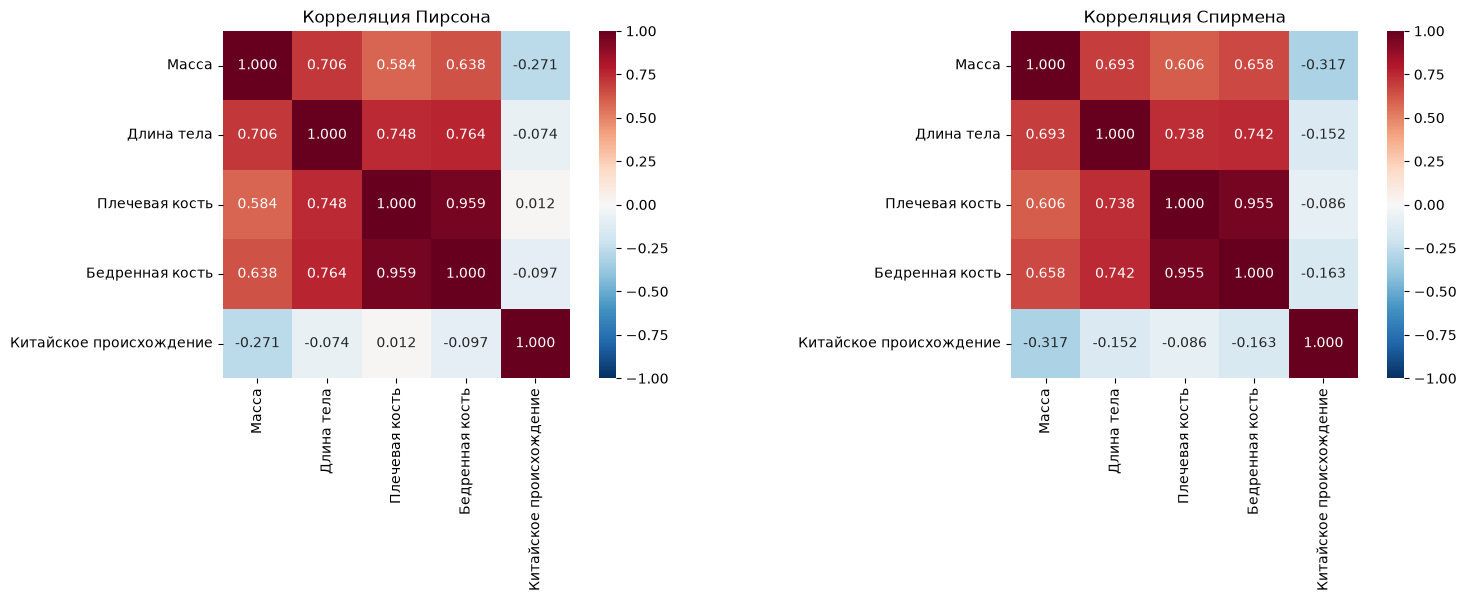

In [182]:
import seaborn as sns
corr_data = pd.DataFrame({
    "Масса": mass,
    "Длина тела": b_length,
    "Плечевая кость": h_length,
    "Бедренная кость": f_length,
    "Китайское происхождение": ancestry
})
pearson_corr = corr_data.corr(method="pearson")
spearman_corr = corr_data.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)
axes[0].set_title("Корреляция Пирсона")
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)
axes[1].set_title("Корреляция Спирмена")
plt.tight_layout()
plt.show()

Корреляционный анализ по методам Пирсона и Спирмена показал наличие положительных связей между величинами макак. Наиболее сильная корреляция наблюдается между длинами плечевой и бедренной костей (r = 0,959; ρ = 0,955). Также выявлена сильная положительная корреляция между длиной тела и длинами костей (r = 0,748–0,764).

Доля китайского происхождения характеризуется слабыми отрицательными корреляциями с исследуемыми величинами. Наиболее выраженная связь наблюдается с массой тела (r = −0,271; ρ = −0,317).

Коэффициенты Пирсона и Спирмена дают сходные результаты, что подтверждает согласованность оценок линейных и монотонных взаимосвязей между исследуемыми величинами.

<a id="normalization"></a>
### Нормализация. Диаграмма размаха

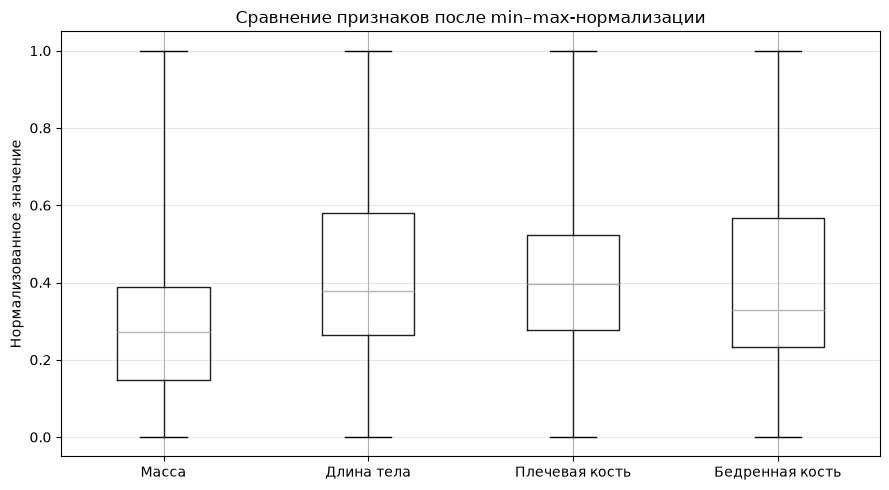

In [152]:
import matplotlib.pyplot as plt

data = complete[["kg", "C-R curved", "R humeral max", "R femoral max"]].copy()
normalized = (data - data.min()) / (data.max() - data.min())
normalized.columns = [
    "Масса",
    "Длина тела",
    "Плечевая кость",
    "Бедренная кость"
]
normalized.boxplot(figsize=(9, 5), whis=(0, 100))
plt.title("Сравнение признаков после min–max-нормализации")
plt.ylabel("Нормализованное значение")
plt.ylim(-0.05, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

На диаграмме размаха представлены масса тела, длина тела и длины плечевой и бедренной костей после min–max-нормализации. Каждая величина приведена к диапазону [0;1], что позволяет сопоставить положение медиан и межквартильные размахи относительно собственного диапазона величины.

Прямоугольники показывают межквартильный диапазон, линия внутри показывают медиану.

Медианы всех четырёх величин расположены ниже середины диапазона.

<a id="extra-task"></a>
## Доп задание по массе

<a id="extra-samples"></a>
### Создание выборок без возвращения, каждая по 50 значениями

In [174]:
rng = np.random.default_rng(42)
population = complete["kg"].to_numpy()
N = len(population)
n = 50
repeats = 1000
samples = np.array([
    rng.choice(population, size=n, replace=False)
    for _ in range(repeats)
])
print("Размер генеральной совокупности:", N)
print("Количество выборок:", repeats)
print("Размер каждой выборки:", n)

Размер генеральной совокупности: 134
Количество выборок: 1000
Размер каждой выборки: 50


<a id="extra-statistics"></a>
### Рассчитываем характеристики всех выборок

In [175]:
sample_stats = pd.DataFrame({
    "Среднее": samples.mean(axis=1),
    "Медиана": np.median(samples, axis=1),
    "Дисперсия": samples.var(axis=1, ddof=1),
    "Стандартное отклонение": samples.std(axis=1, ddof=1)
})
sample_stats.head(10)

,Среднее,Медиана,Дисперсия,Стандартное отклонение
0,11.2480,10.905,12.716180,3.565975
1,9.8824,9.490,9.676631,3.110728
2,10.9040,10.660,9.849539,3.138397
3,11.0572,10.775,14.360580,3.789536
4,10.6764,10.185,10.360260,3.218736
5,10.8154,10.805,8.858985,2.976405
6,10.6404,9.770,15.199535,3.898658
7,10.0554,9.890,7.150315,2.674007
8,9.9978,9.415,10.805536,3.287177
9,10.4178,10.225,12.947213,3.598224


<a id="extra-comparison"></a>
### Сравниваем характеристики с генеральной совокупностью

In [177]:
population_stats = {
    "Среднее": population.mean(),
    "Медиана": np.median(population),
    "Дисперсия": population.var(ddof=1),
    "Стандартное отклонение": population.std(ddof=1)
}
comparison = pd.DataFrame({
    "Генеральная совокупность": population_stats,
    "Среднее по 1000 выборкам": sample_stats.mean(),
    "Разброс оценок": sample_stats.std(ddof=1)
})
comparison["Отклонение"] = (
    comparison["Среднее по 1000 выборкам"]
    - comparison["Генеральная совокупность"]
)
display(comparison.round(4))

,Генеральная совокупность,Среднее по 1000 выборкам,Разброс оценок,Отклонение
Среднее,10.3780,10.3723,0.3947,-0.0057
Медиана,9.8150,9.9074,0.4538,0.0924
Дисперсия,12.1619,12.1417,2.5193,-0.0202
Стандартное отклонение,3.4874,3.4653,0.3658,-0.0221


<a id="extra-plots"></a>
### Графики сравнения характеристик

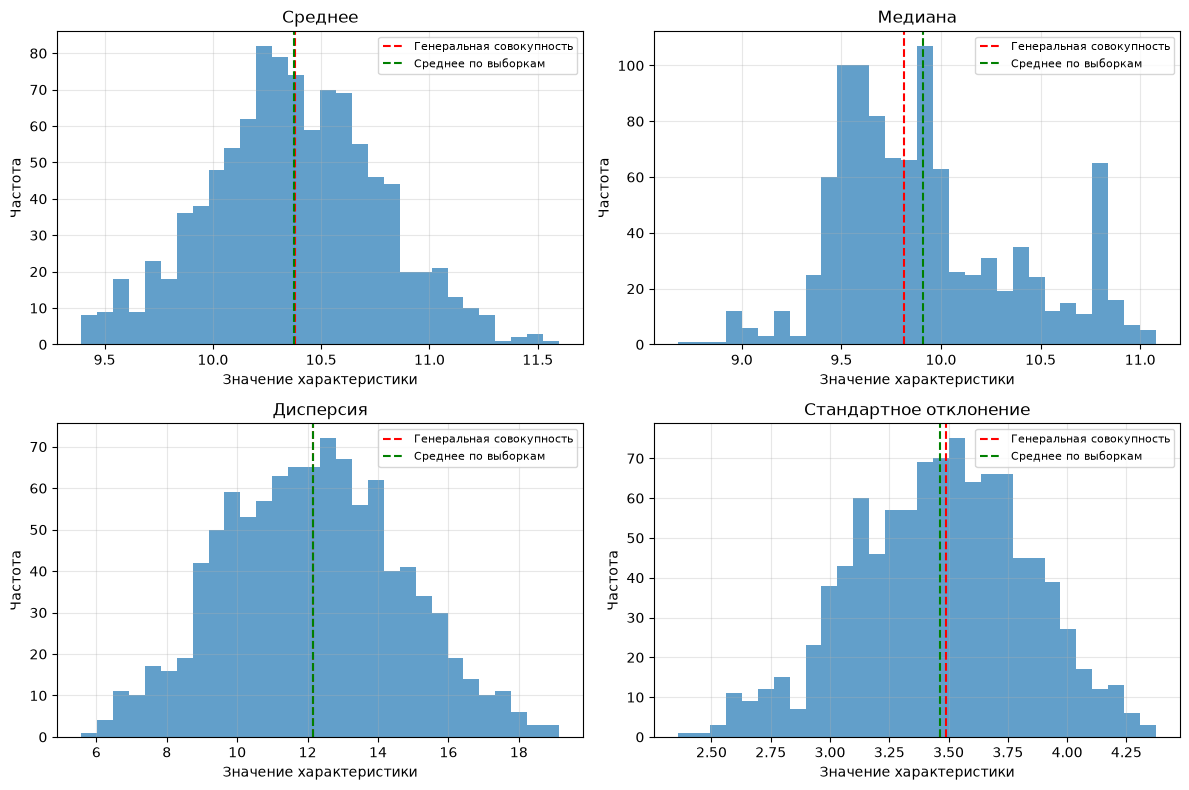

,Генеральная совокупность,Среднее по 1000 выборкам,"Отклонение, %"
Среднее,10.3780,10.3723,0.0552
Медиана,9.8150,9.9074,0.9412
Дисперсия,12.1619,12.1417,0.1660
Стандартное отклонение,3.4874,3.4653,0.6347


In [180]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, name in zip(axes.flat, sample_stats.columns):
    ax.hist(sample_stats[name], bins=30, alpha=0.7)
    ax.axvline(
        population_stats[name],
        color="red",
        linestyle="--",
        label="Генеральная совокупность"
    )
    ax.axvline(
        sample_stats[name].mean(),
        color="green",
        linestyle="--",
        label="Среднее по выборкам"
    )
    ax.set_title(name)
    ax.set_xlabel("Значение характеристики")
    ax.set_ylabel("Частота")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

comparison["Отклонение, %"] = (
    abs(comparison["Среднее по 1000 выборкам"] -
        comparison["Генеральная совокупность"])
    / abs(comparison["Генеральная совокупность"]) * 100
)
display(comparison[[
    "Генеральная совокупность",
    "Среднее по 1000 выборкам",
    "Отклонение, %"
]].round(4))

Средние характеристики 1000 выборок без возвращения, 50 значений каждая, очень близки к характеристикам генеральной совокупности.
Среднее значение уменьшилось на 0,0552%, медиана увеличилась на 0,9412%, дисперсия уменьшилась на 0,1660%, стандартное отклоненеие уменьшилось на 0,6347%.

<a id="lab-resume"></a>
## Lab resume

Было выявлено, что все величины (масса тела, длина тела, длина плечевой кости, длина бедренной кости) попарно зависимы.

Было выявлено, что все 4 величины зависят и от пола (у самцов больше средние значения всех 4х величин), и от доли китайского происхождения: самый яркий пример: на диаграмме видно, что масса тела уменьшается с ростом доли китайского происхождения.

В ходе лабораторной работы были исследованы четыре случайные величины, характеризующие макак: масса тела, длина тела, длины плечевой и бедренной костей. Рассчитаны различные характеристики, изучены распределения и выявлены взаимосвязи между величинами. Наиболее сильная корреляция обнаружена между длинами плечевой и бедренной костей.

Дополнительно исследованы 1000 выборок без возвращения по 50 значений массы тела каждая. Полученные результаты показали, что средние характеристики выборки близки к характеристикам генеральной совокупности.